TokaMaker Example: Breakdown and start-up design for ARC V3A {#doc_tMaker_ARC_ex4}
==========
This example designs the first two seconds of an ARC V3A discharge, from coils charged in an empty vacuum vessel to a 0.57 MA plasma, using TokaMaker for every magnetic calculation. It demonstrates:

 - Building a circuit model of the coils **and** the passive conducting structure (vacuum vessel and blanket) from a TokaMaker mesh, with the structure cut into segments that TokaMaker treats as coils
 - Optimising every power-supply voltage, from premagnetisation through breakdown to a 100 kA plasma channel, as a single convex optimisation problem with the breakdown criteria as hard constraints
 - Checking the breakdown against the avalanche physics (field-line connection length and Townsend criterion)
 - Ramping the plasma current with TokaMaker free-boundary equilibria to 0.57 MA, coupled to the same circuit model, with the breakdown re-optimised together with the ramp

The machine is the ARC V3A design described in Appendix A of Hillesheim et al., "Overview of the physics basis for the ARC fusion power plant", Journal of Plasma Physics (2026), [doi:10.1017/S0022377826101706](https://doi.org/10.1017/S0022377826101706). The mesh and gEQDSK used here are the ones in the `ARC` example folder (\ref doc_tMaker_ARC_ex1).

**Runtime:** about 4 minutes on a laptop, most of it in the TokaMaker ramp (step 6).

**Prerequisites:** besides OpenFUSIONToolkit and the usual scientific Python packages, the optimizer uses the conic solver [Clarabel](https://clarabel.org) (`pip install clarabel`). The helper modules `startup_model.py`, `startup_optimizer.py` and `startup_plots.py` in this folder contain the model, the optimizer and the figures; this notebook explains and drives them.

## The start-up problem

A tokamak discharge starts in a vessel filled with neutral gas at about a millipascal. The central solenoid (CS) is first charged (**premagnetisation**), then its current is swung, which induces a toroidal electric field $E_\phi$. A free electron accelerated by $E_\phi$ ionises gas molecules, and if it travels far enough before hitting the wall, the ionisation multiplies into an avalanche (**breakdown**). The plasma current then rises while the plasma heats up and burns through its impurity radiation (**burn-through**), and finally the plasma becomes a proper equilibrium whose current is ramped up (**current ramp**).

Breakdown needs two things at once in some region of the vessel:

 1. enough toroidal electric field $E_\phi$, and
 2. a very small poloidal field $B_p$ (a **field null**). Field lines are then nearly toroidal and run for kilometres before they hit the wall, so electrons can travel far enough to start the avalanche.

On alarge future machine such as ARC this is difficult, for three reasons:

 - **Eddy currents.** The thick vacuum vessel and blanket are good conductors with wall time constants of tens of milliseconds. Every change of coil current induces eddy currents in them, and these produce tens of millitesla at the null, while breakdown needs a few millitesla or less. The structure therefore has to be part of the design model.
 - **Limited supplies.** The supply voltages are limited (here we just use an estimate of $\pm 5$ kV).
 - **Flux budget.** Every volt-second spent on breakdown and the ramp is unavailable for the flat-top, so the design should leave as much transformer flux as possible.

## The approach

The start-up is designed in two stages that share one circuit model:

| Stage | Time | Plasma model | Method |
|---|---|---|---|
| **1. Breakdown and early plasma** | $-2$ s to $0.5$ s | none, then a current-carrying ring (channel) | one convex optimisation problem: premagnetisation currents and all supply voltages |
| **2. Current ramp** | $0.5$ s to $1.8$ s | TokaMaker free-boundary equilibria | Picard iteration between TokaMaker and a convex problem that also re-optimises stage 1 |

The key observation for stage 1 is that the coils and structure form a **linear circuit**. If the supply voltages are held constant on each time step, every current, field and electric field at every time is a linear function of the decision variables. The breakdown criteria then become linear and second-order-cone constraints, and the conic solver finds the global optimum, with no weights to tune.

## Setup Python environment

In [1]:
import os
import sys
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where the module is located. This can be done either through the `PYTHONPATH` environment variable or within a script using `sys.path.append()` as below, where we look for the environment variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

We also import the three helper modules that live next to this notebook.

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import load_gs_mesh
from OpenFUSIONToolkit.TokaMaker.util import read_eqdsk, create_isoflux

from startup_model import segment_conductors, MachineModel, CircuitModel, FieldTracer, townsend_window, paschen_Emin
from startup_optimizer import StartupProblem, GSRamp
import startup_plots as splt

## 1. Machine model

### Load the mesh and the toroidal field

The ARC V3A mesh (built in \ref doc_tMaker_ARC_ex1) contains 16 coils (three CS pairs and five PF pairs) and three passive conducting regions: the inner and outer vacuum vessel and the blanket, each with its resistivity $\eta$. The vacuum toroidal field $F_0 = R B_\phi$ is taken from the reference gEQDSK, which is downloaded from [Zenodo](https://zenodo.org/records/19498373) into the `ARC` folder if it is not already there.

In [3]:
mesh_pts, mesh_lc, mesh_reg, coil_dict, cond_dict = load_gs_mesh('../../ARC/arc_v3a_mesh.h5')
eqdsk_file = '../../ARC/geqdsk-ARCv3a'
if not os.path.exists(eqdsk_file):  # same Zenodo record as the ARC examples
    import urllib.request
    print('Downloading geqdsk-ARCv3a from Zenodo...', end=' ', flush=True)
    urllib.request.urlretrieve('https://zenodo.org/records/19498373/files/geqdsk-ARCv3a?download=1', eqdsk_file)
    print('done.')
eqdsk = read_eqdsk(eqdsk_file)
F0 = eqdsk['rcentr']*eqdsk['bcentr']
print('coils:', ', '.join(coil_dict))
for name, reg in cond_dict.items():
    if reg.get('eta', -1) > 0:
        print(f"conductor {name:13s} eta = {reg['eta']:.1e} Ohm m")
print(f'F0 = R B_phi = {F0:.1f} T m')

coils: CS1U, CS1L, CS2U, CS2L, CS3U, CS3L, PF1U, PF1L, PF2U, PF2L, PF3U, PF3L, PF4U, PF4L, PF5U, PF5L
conductor VESSEL_INNER  eta = 6.0e-07 Ohm m
conductor VESSEL_OUTER  eta = 6.0e-07 Ohm m
conductor BLANKET       eta = 7.4e-07 Ohm m
F0 = R B_phi = -52.7 T m


### Design inputs: structure segmentation and hardware limits

The rest of the machine description is a handful of numbers:

 - **Structure segments.** How finely each conducting region is cut into segments (see below). The blanket is 22 cm thick, so it gets the most segments, which k-means clustering also splits through its thickness.
 - **Coil current limits.** Each coil's limit is a current-density limit $J_{max}$ times its cross-section, divided by its turns.
 - **Supply voltages.** The limit is the same $\pm 5$ kV on every coil circuit. This is a provisional scoping value, not a design figure.
 - **Open coils.** The vertical-stability coils PF5U/L are not used during start-up.

In [4]:
# passive structure: number of segments per conducting region, and the centre used to order them
SEGMENTS = {'n_segments': {'VESSEL_INNER': 48, 'VESSEL_OUTER': 64, 'BLANKET': 96},
            'center': [4.2, 0.0]}
J_MAX = 40.0e6          # coil current-density limit [A/m^2] -> per-turn current limit of each coil
V_MAX = 5000.0          # supply voltage limit of every coil circuit [V] (provisional)
EXCLUDE = ['PF5']       # PF5U/L, the vertical-stability pair, stay open (unpowered) during start-up

### Segment the passive structure

Eddy currents flow toroidally in the vessel and blanket, with a distribution set by the changing flux. We represent them by cutting every conducting region into segments, each of which carries one unknown current. Within a segment the current density is taken $\propto 1/R$. That is the distribution a uniform toroidal electric field drives, and it is accurate as long as segments are small compared with the scale over which $E_\phi$ varies. A segment's resistance follows from the resistivity:
$$ R_{seg} = \frac{2\pi\,\eta}{\sum_{cells} A_{cell}/R_{cell}}. $$

`segment_conductors` returns a new region map with one region per segment, TokaMaker coil definitions for the segments (1 turn each), and the remaining non-conducting regions.

In [5]:
seg_reg, segments, seg_coils, vac_dict = segment_conductors(mesh_pts, mesh_lc, mesh_reg, cond_dict, **SEGMENTS)
for name in SEGMENTS['n_segments']:
    R_seg = np.array([s['R_ohm'] for s in segments if s['region'] == name])
    print(f'{name:13s} {len(R_seg):3d} segments, resistance {R_seg.min()*1e6:.0f} to {R_seg.max()*1e6:.0f} micro-Ohm')

VESSEL_INNER   48 segments, resistance 1940 to 5847 micro-Ohm
VESSEL_OUTER   64 segments, resistance 935 to 2673 micro-Ohm
BLANKET        96 segments, resistance 1626 to 8696 micro-Ohm


### Set up TokaMaker with the segments as coils

TokaMaker is set up as usual with `setup_model`, except that the conducting regions are replaced by the segment "coils". TokaMaker then computes the full finite-element mutual-inductance matrix of coils and structure itself, and every field map below comes straight from its finite-element model.

**Note:** Only a single `OFT_env` instance can be used per python kernel, so this class should only be instantiated **once** in a given Jupyter notebook or python script.

In [6]:
myOFT = OFT_env(nthreads=2)
mygs = TokaMaker(myOFT)
# setup_model modifies the dictionaries it is given, so pass copies
mygs.setup_model(r=mesh_pts, lc=mesh_lc, reg=seg_reg, cond_dict=copy.deepcopy(vac_dict),
                 coil_dict=copy.deepcopy({**coil_dict, **seg_coils}), order=2, F0=F0)
mygs.settings.pm = False         # silence the per-iteration solver output from here on
mygs.update_settings()

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        v26.9
Development branch:  tmtx-fsa-geometry
Revision id:         b50e6ddb

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.060E+02
    # of points  =    9281
    # of edges   =   27632
    # of cells   =   18352
    # of boundary points =     208
    # of boundary edges  =     208
    # of boundary cells  =     208
  Resolution statistics:
    hmin =  1.000E-02
    hrms =  1.236E-01
    hmax =  3.005E-01
  Surface grounded at vertex    2770


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing f

### Build the machine model

`MachineModel` asks TokaMaker for three things:

 - the $1/R$ current distribution of every segment (`set_coil_current_dist`);
 - the mutual-inductance matrix $L$ of all coils and segments (`Lcoils`);
 - the vacuum flux of a unit current in each coil and segment (`vac_solve`), from which any field can later be evaluated as a linear combination.

This takes about ten seconds (224 vacuum solves). As a check, the slowest structure time constants (the $L/R$ eigenvalues of the structure on its own) are printed: these are the decay times of the eddy currents.

In [7]:
t0 = time.time()
model = MachineModel(mygs, (mesh_pts, mesh_lc, mesh_reg), coil_dict, segments, F0, J_max=J_MAX)
print(f'{model.nc} coils + {model.ns} structure segments in {time.time()-t0:.0f} s')
print('slowest structure time constants [ms]:', np.round(model.structure_time_constants()[:5]*1e3, 1))

computing the vacuum flux of a unit current in each of 224 units ...
16 coils + 208 structure segments in 9 s
slowest structure time constants [ms]: [331.7 186.8  91.4  75.5  63. ]


## 2. Circuit model

The state $x$ holds one current per driven coil circuit (per-turn amperes, as `set_coil_currents` takes them) and one per structure segment. The circuit equation is
$$ M\,\dot{x} + R\,x = S\,V, $$
where $M$ is the inductance matrix (from TokaMaker), $R$ the resistances (zero for the superconducting coils), $V$ the supply voltages and $S$ maps each supply to its coil. Once the plasma exists, its current $I_p$ is appended to the state (step 3).

The voltages are held constant on each time step, so the equation can be integrated **exactly** over a step of length $\Delta t$ with one matrix exponential:
$$ x_k = A\,x_{k-1} + B\,V_k,\qquad \exp\left(\begin{bmatrix} -M^{-1}R & M^{-1}S\\ 0 & 0\end{bmatrix}\Delta t\right) = \begin{bmatrix} A & B\\ 0 & I\end{bmatrix}. $$
This has no time-step error, and works for $R=0$. Stage 1 and stage 2 each get their own copy of the circuit, since stage 1 adds the plasma channel to its copy.

In [8]:
circ1 = CircuitModel(model, V_MAX, exclude=EXCLUDE)     # stage 1 (the plasma channel is added to it)
circ2 = CircuitModel(model, V_MAX, exclude=EXCLUDE)     # stage 2 (TokaMaker carries the plasma)
print(f'{circ1.ncirc} driven circuits: {", ".join(circ1.circ_names)}')
print(f'state size {circ1.nx} = {circ1.ncirc} coil circuits + {model.ns} segments')

14 driven circuits: CS1U, CS1L, CS2U, CS2L, CS3U, CS3L, PF1U, PF1L, PF2U, PF2L, PF3U, PF3L, PF4U, PF4L
state size 222 = 14 coil circuits + 208 segments


## 3. The start-up scenario

The scenario describes what we want from the start-up, independently of the machine.

**Time grid.** The run starts at $t=-2$ s with the coils premagnetised and the structure at rest (no eddy currents). Steps are 0.1 s during premagnetisation, 10 ms from $-0.3$ s through the breakdown window $0 \le t \le 50$ ms, and 25 ms during the early plasma phase until the hand-off to the GS ramp at $t = 0.5$ s.

**Breakdown criteria**, imposed at 49 points covering a disk of radius 0.6 m centred at $R=4.4$ m, on every time step of the window:

 1. A floor on the toroidal electric field, $s\,E_\phi \ge E_{min} = 0.3$ V/m, where $s$ is the sign of the plasma current.
 2. The **Leuer criterion** on the field-line length. An electron must travel a connection length $L_c \sim a\,B_\phi/B_p$ along the field before reaching the wall, and the avalanche needs $E_\phi L_c$ to be large enough. This is expressed as
$$ \frac{E_\phi\,B_\phi}{B_p} \;\ge\; m\,E^*, \qquad E^* = 1000\ \text{V/m}, $$
with margin $m=1$. Each step's $E_\phi$ is checked against $B_p$ at both ends of the step.

**Early plasma channel.** Once the window ends, the plasma is a ring of radius $a = 0.58$ m at $R_c = 4.0$ m: the inboard-limited circle where the first TokaMaker equilibrium of the ramp sits. It is an extra circuit element:

 - Its self-inductance is $L_p = \mu_0 R_c\left(\ln\frac{8R_c}{a} - 2 + \frac{l_i}{2}\right)$.
 - Its mutual inductance with every coil and segment comes from the TokaMaker flux maps.
 - Its resistance is the Spitzer resistance at a prescribed temperature, rising from 5 eV to 100 eV with a 0.1 s time constant. This is a placeholder for a burn-through model.
 - It has no supply: it is driven only by the changing flux of the coils and structure.

The optimiser must take its current to exactly $I_p = 100$ kA at $t = 0.5$ s, the first current of the ramp, and while it does so:

 - **Radial force balance:** the external vertical field at the channel must match the Shafranov value $B_v = -\frac{\mu_0 I_p}{4\pi R_c}\left(\ln\frac{8R_c}{a} + \frac{l_i}{2} - \frac{3}{2}\right)$ within 20% (plus 0.2 mT), and the radial field must stay equally small.
 - **Stability:** the decay index $n = -\frac{R_c}{B_z}\frac{\partial B_z}{\partial R}$ must lie between 0 (radially stable) and 1 (vertically stable).
 - **Burn-through drive:** the external $E_\phi$ at the channel must stay above 0.3 V/m until $t = 0.25$ s.
 - **Monotone current:** $I_p$ may never fall. Otherwise the optimiser would let the current collapse and re-drive it to save flux, and a real discharge would be lost.

**Objective.** Maximise the flux left at the centre of the region at the hand-off. This is the transformer flux still available to drive the rest of the pulse.

**Ramp (stage 2).** $I_p$ rises linearly towards 1 MA (0.57 MA at 1.8 s, the end of this example). The target boundary grows from the channel circle to an elongated, inboard-limited shape, and $T_e$ rises from 100 eV.

In [9]:
STAGE1 = {
    'ip_sign': 1,                                   # sign of the plasma current (and of E_phi)
    'time': {'t_start': -2.0,                       # premagnetised coils, structure at rest
             't_fine_start': -0.3, 't_fine_end': 0.05, 't_end': 0.5,
             'dt_pre': 0.1, 'dt_fine': 0.01, 'dt_ramp': 0.025},     # time steps [s]
    'region': {'R': 4.4, 'Z': 0.0, 'radius': 0.6,   # breakdown region: a disk [m]
               'n_rings': 3, 'n_per_ring': 8},      # 49 constraint points over the disk
    'breakdown': {'window': [0.0, 0.05],            # breakdown must hold over 0-50 ms
                  'E_min': 0.3,                     # V/m, toroidal electric field floor
                  'E_star': 1000.0,                 # V/m, Leuer threshold E_phi B_phi / B_p >= m E*
                  'margin': 1.0},                   # m
    'plasma': {'Rc': 4.0, 'Zc': 0.0, 'a': 0.58,     # early channel: inboard-limited ring [m]
               'li': 0.5, 'Zeff': 2.0,
               'Te0': 5.0, 'Te1': 100.0, 'tau_Te': 0.1,       # prescribed burn-through T_e(t) [eV, s]
               'Ip_target': 1.0e5,                  # A at t_end: the first current of the GS ramp
               'force_balance': {'frac': 0.2, 'B_tol': 2.0e-4},   # |B_z - B_v,req| <= 20% + 0.2 mT
               'decay_index': [0.0, 1.0],           # radially and vertically stable channel
               'E_min_burn': 0.3, 't_burn_end': 0.25},            # V/m at the channel through burn-through
    'regularization': {'dV': 3.0e-2, 'V': 1.0e-4},  # weak smoothing / size penalties on V (relative to V_max)
}

RAMP = {'ramp': {
    'time': {'t_start': 0.5, 't_end': 1.8, 'dt': 0.1},
    'Ip': [[0.5, 1.0e5], [3.0, 1.0e6]],             # [t, I_p] keyframes: 0.57 MA at 1.8 s
    'shape': [[0.5, 4.00, 0.0, 0.58, 1.00, 0.00],   # [t, R0, Z0, a, kappa, delta] keyframes:
              [3.0, 4.40, 0.0, 0.98, 1.30, 0.20]],  # inboard-limited, growing and elongating
    'Te': [[0.5, 100.0], [1.5, 400.0], [3.0, 800.0]],   # [t, T_e] keyframes for the plasma resistance
    'Zeff': 2.0,
    'ffp': [1.5, 2.0], 'pp': [4.0, 1.0], 'Ip_ratio': 1.0,   # TokaMaker profile shapes
    'n_iso': 16, 'iso_weight': 10.0,                # isoflux points per slice, TokaMaker weight
    'shape_tol': 0.02,                              # m, boundary error that costs 1 in the convex program
    'dV': 1.0, 'V_reg': 1.0e-4,                     # voltage smoothing / size weights
    'seed_weight': 100.0, 'pin_weight': 1000.0,     # TokaMaker pin to the coil trajectory
    'relax': 0.5, 'prox_weight': 0.1,               # Picard under-relaxation, proximal weight
    'joint': {'flux_slack_Wb': 0.2},                # stage-1 flux may drop by at most 0.2 Wb
    'max_iter': 15,
}}

### Plot the machine and the scenario
Dark coils are driven; the light pair (PF5) stays open. The coloured outlines are the structure segments, shaded alternately within each region. The dashed circle is the breakdown region, the orange circle the early plasma channel, and the purple outlines the ramp's target shapes.

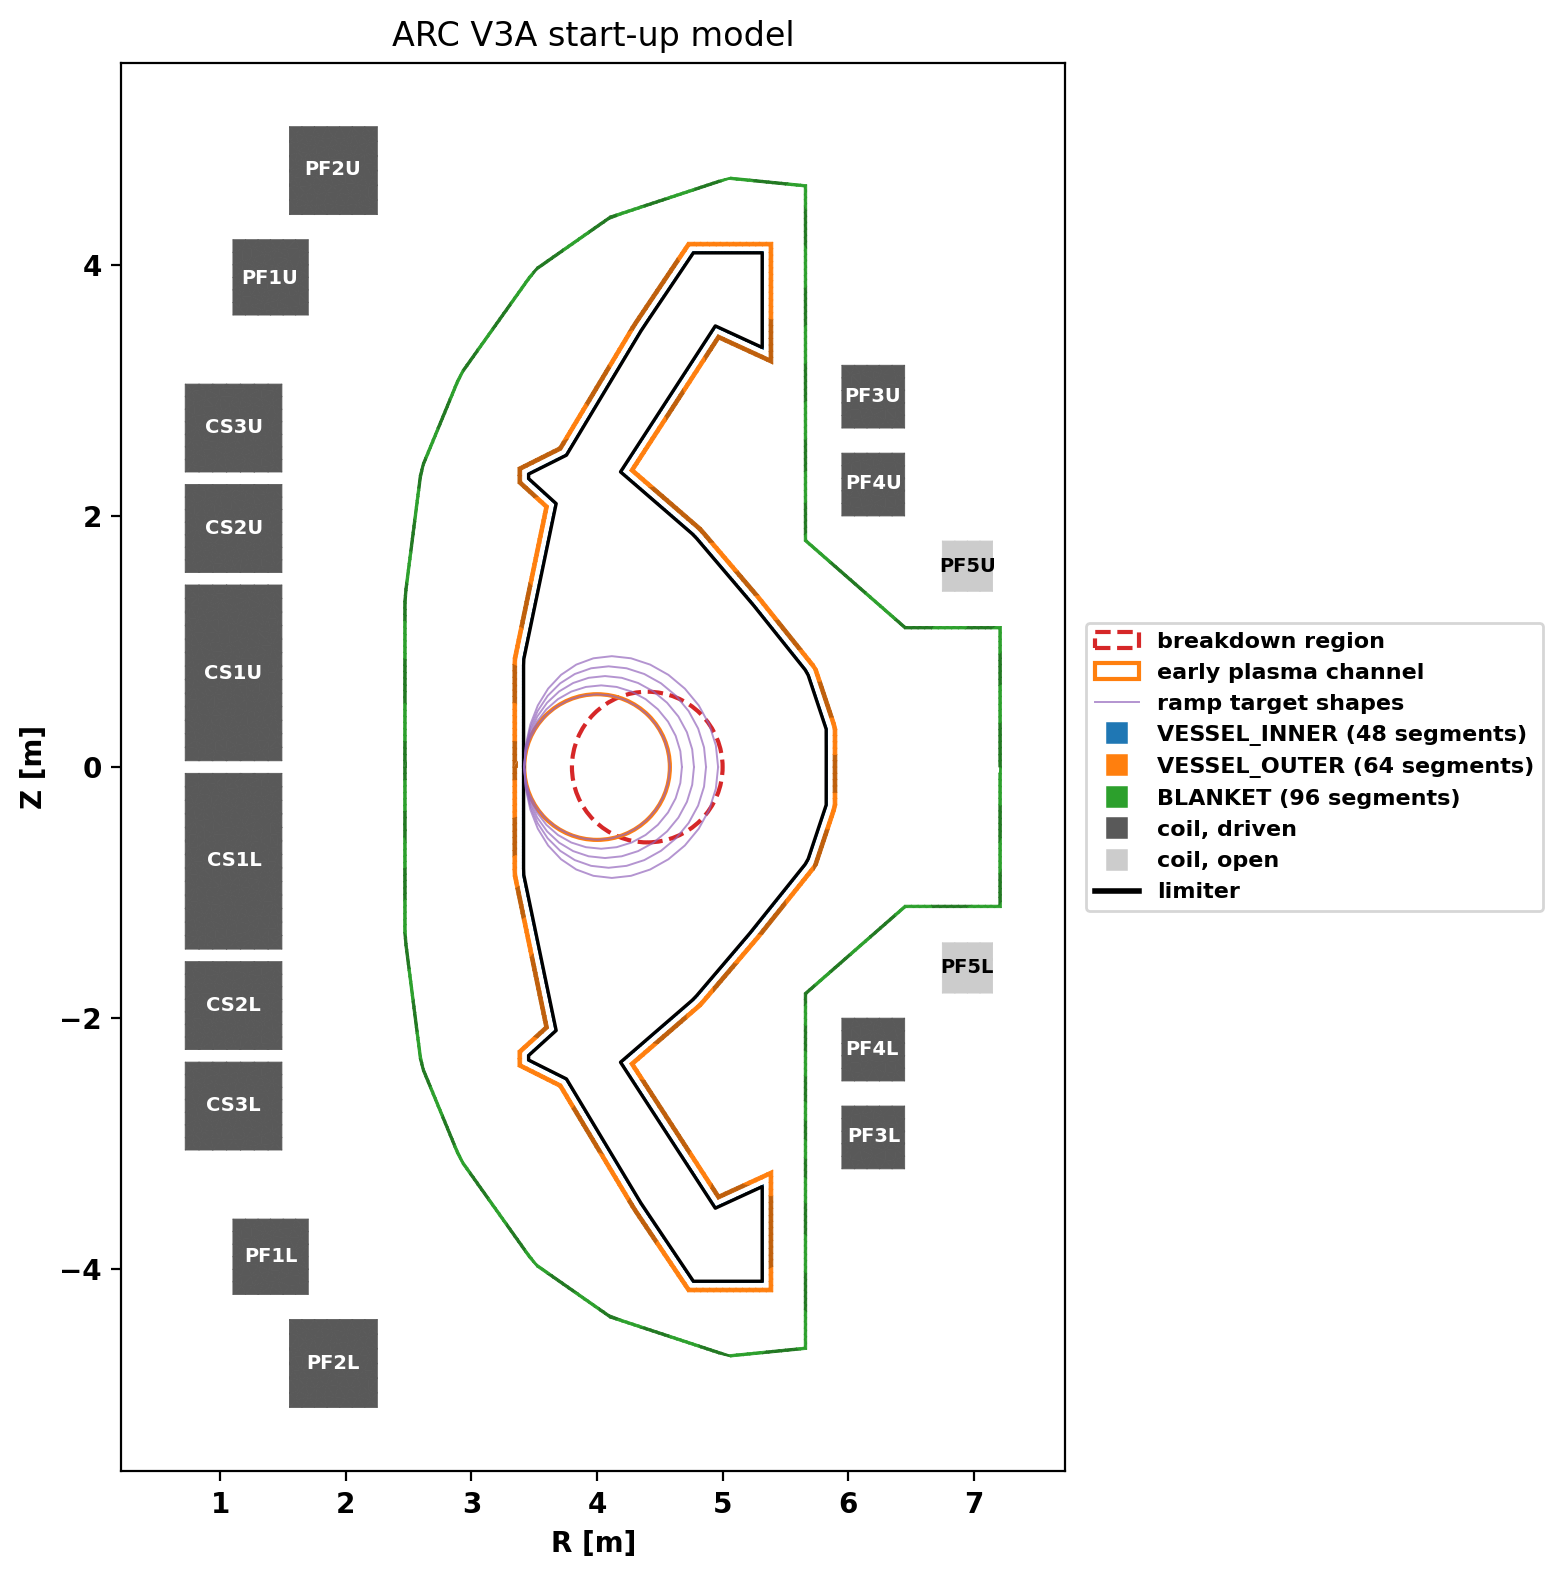

In [10]:
geom = splt.MeshGeometry(model)
used = np.abs(circ1.T).sum(axis=1) > 0
ramp_t = np.arange(0.5, 1.81, 0.1)
shapes = [create_isoflux(32, *[np.interp(t, *zip(*[(k[0], k[j]) for k in RAMP['ramp']['shape']])) for j in range(1, 6)])
          for t in ramp_t[::3]]
rg, pl = STAGE1['region'], STAGE1['plasma']
fig = splt.plot_machine(model, geom, used, (rg['R'], rg['Z'], rg['radius']), (pl['Rc'], pl['Zc'], pl['a']), shapes)
plt.show()

## 4. Stage 1: breakdown and early plasma as one convex problem

**Variables.** The decision variables are the premagnetisation current $I_0$ of each of the 14 driven circuits (with the structure at rest at $t=-2$ s) and the 14 supply voltages on each of the 70 time steps.

**Everything is affine.** Propagating the exact step $x_k = A_k x_{k-1} + B_k V_k$ gives every state as an affine map of the variables,
$$ x_k = G^I_k\,I_0 + G^V_k\,V. $$
Every coil and eddy current, every field at the breakdown points and every $E_\phi$ (the change of flux over a step) is therefore linear in $(I_0, V)$. The plasma resistance changes from step to step, but it is prescribed, so the maps stay affine.

**The constraints are convex:**

 - Coil current and voltage limits, the $E_\phi$ floors, force balance, decay index and monotone $I_p$ are linear inequalities, and the hand-off current is a linear equality.
 - The Leuer criterion, written as $\lVert (B_R, B_Z) \rVert_2 \le \frac{B_\phi}{m E^*}\,s E_\phi$, is a **second-order cone** at each point and time.

**The objective** is linear (the flux at the hand-off), plus two very weak regularisation terms on the voltages.

`StartupProblem.build()` assembles this, and Clarabel solves it to the global optimum in about 20 seconds. This is the main difference from weighted least-squares start-up design, where the answer depends on the weights chosen. (Clarabel may report `AlmostSolved`: converged to slightly relaxed tolerances, which is normal for a problem of this size and scaling.)

In [11]:
s1 = StartupProblem(model, circ1, STAGE1)
t0 = time.time()
s1.build()
status = s1.solve()
res_alone = s1.results()
flux_alone = s1.flux_handoff()
print(f'{status}: {s1.P.nvar} variables, {time.time()-t0:.0f} s')
print(f'flux left at the hand-off: {flux_alone:.2f} Wb, I_p = {s1.s*res_alone["Ip"][-1]/1e3:.0f} kA at t = {s1.t[-1]} s')
k_bd = s1.K[0]
print(f'first window step (t = {s1.t[k_bd]*1e3:.0f} ms): min s*E_phi = {res_alone["E_pts"][k_bd].min():.3f} V/m, '
      f'max |B_p| = {res_alone["B_pts"][k_bd].max()*1e3:.2f} mT, min Leuer = {res_alone["leuer_pts"][k_bd].min():.0f} V/m')

AlmostSolved: 994 variables, 19 s
flux left at the hand-off: 82.31 Wb, I_p = 100 kA at t = 0.5 s
first window step (t = 10 ms): min s*E_phi = 0.355 V/m, max |B_p| = 4.22 mT, min Leuer = 1076 V/m


### What did the optimiser choose?
The breakdown window is shaded. Things to look for:

 - **Coil currents:** CS2, CS3 and PF1 start at their current limits, since more premagnetisation means more flux. CS1 starts at about half its limit.
 - **Supply voltages:** they sit at the $\pm 5$ kV limits for long stretches, so on ARC the breakdown is limited by the supply voltage.
 - **Eddy currents:** the structure current builds up long before breakdown. The optimiser drives a steady loop voltage several wall time constants early, so that the eddy currents settle into a pattern the coils can cancel at the null.
 - **Field in the region:** it drops by about two orders of magnitude into the window, to a few millitesla, and the Leuer quantity rises above $mE^*$ exactly there.
 - **Plasma current:** after the window it rises to 100 kA without ever falling.

These are the stage-1 voltages on their own. Step 6 re-optimises them together with the ramp.

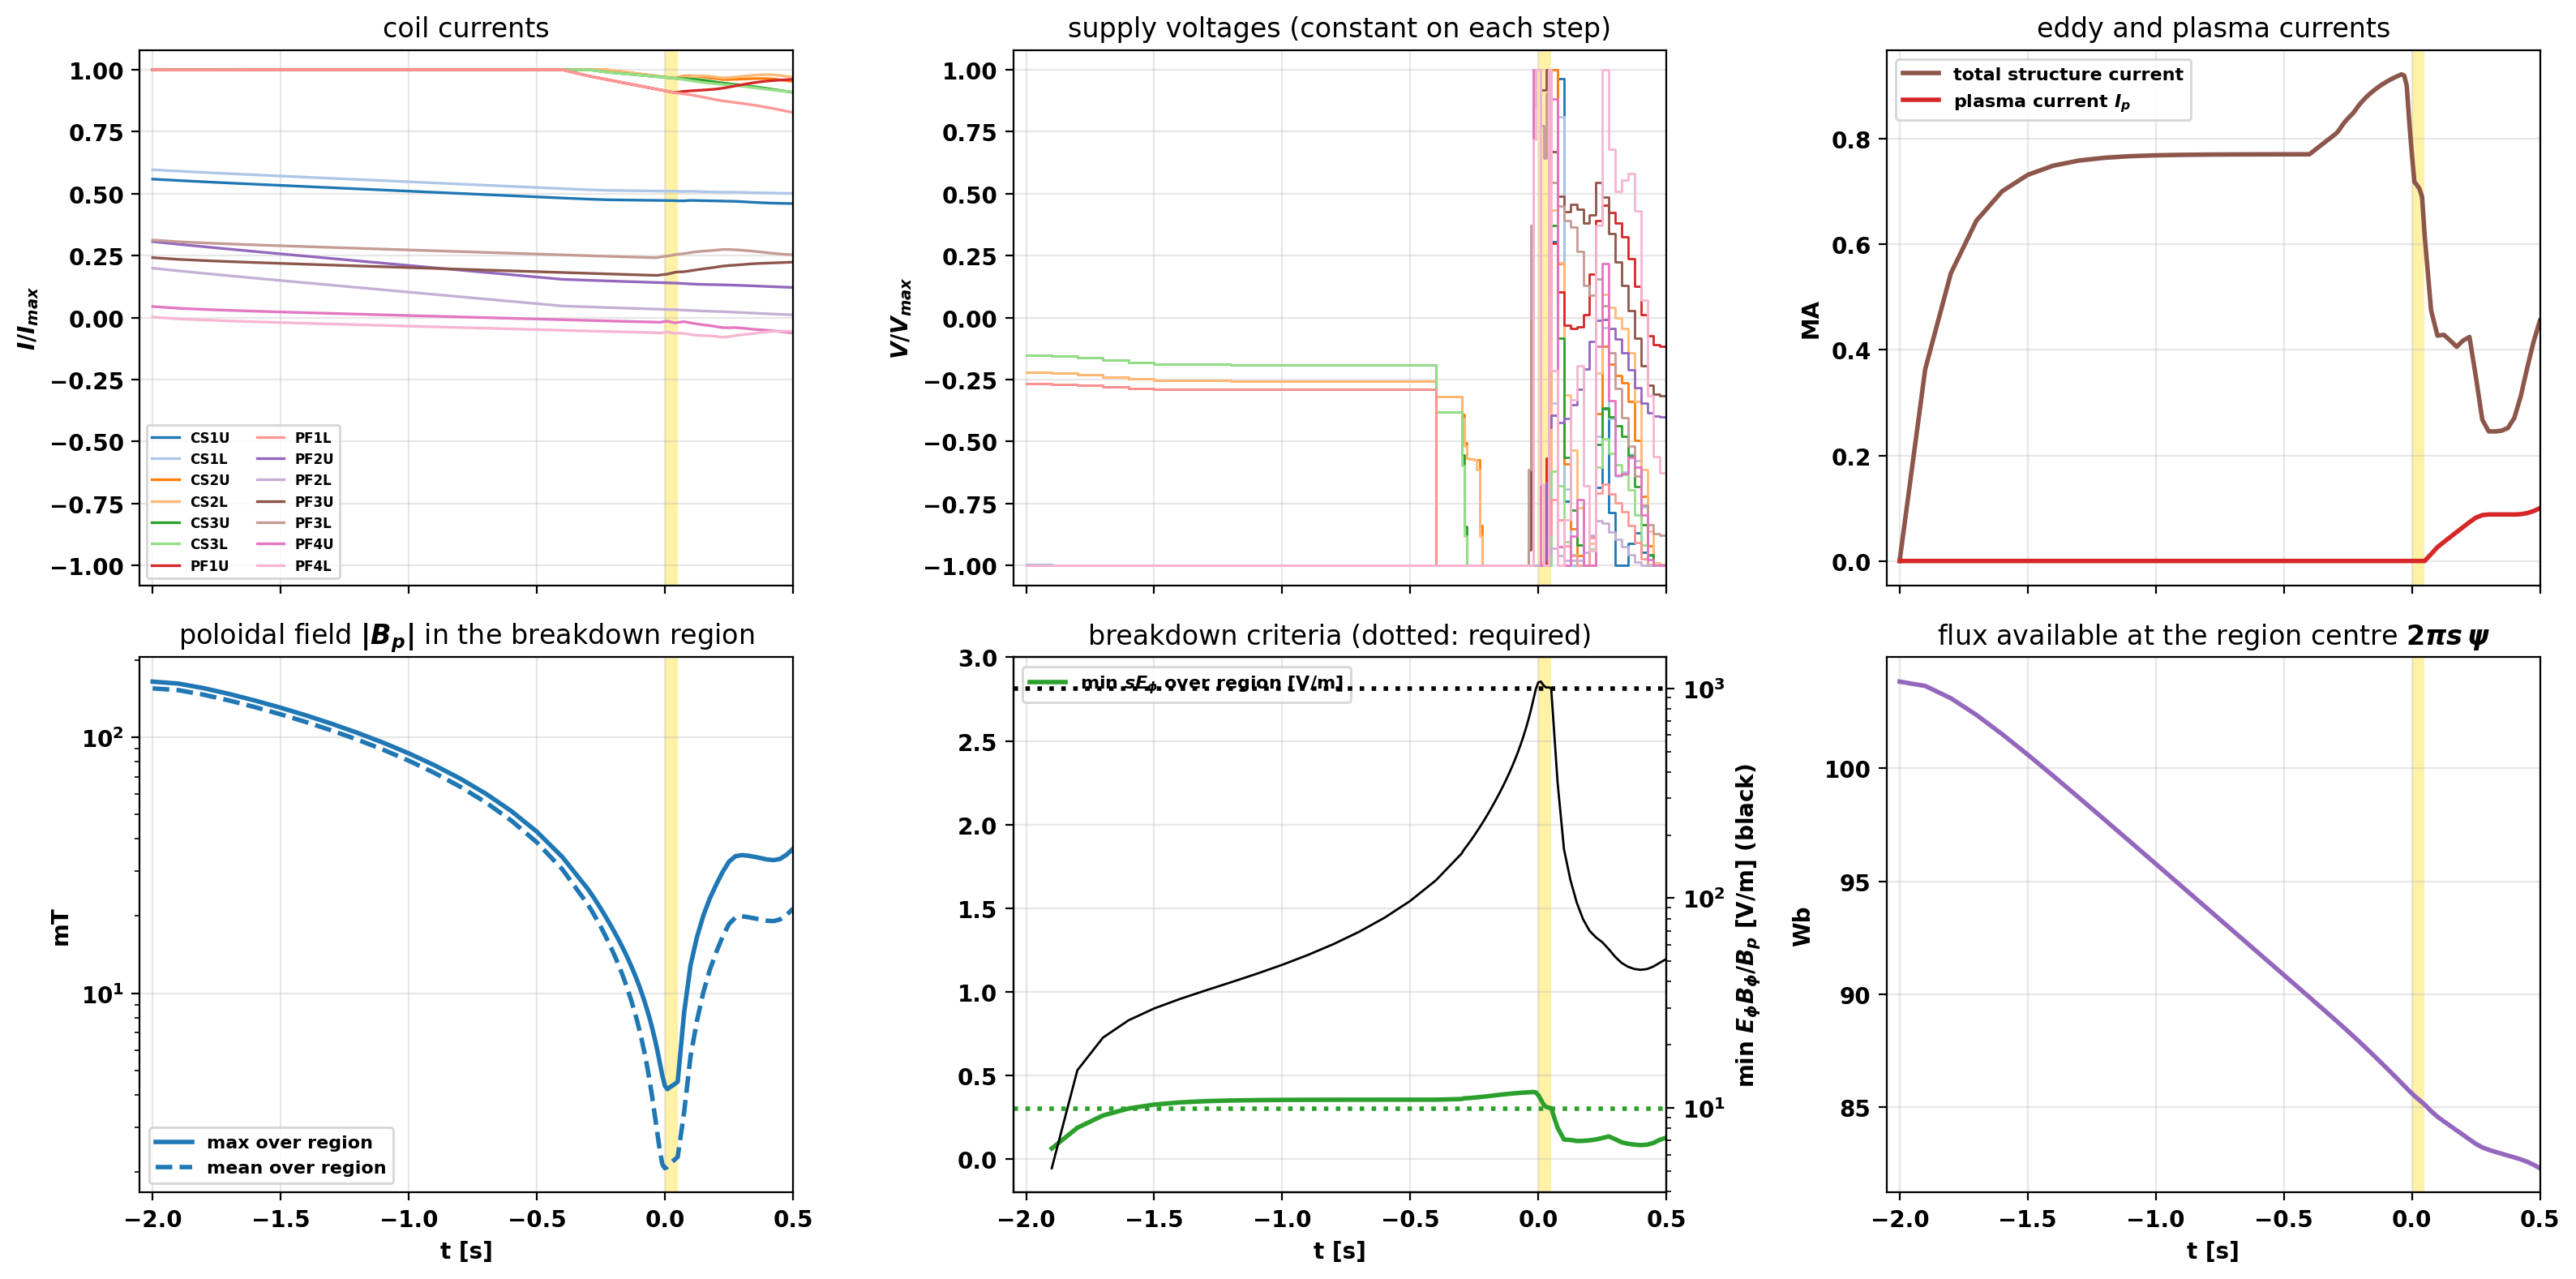

In [12]:
fig = splt.plot_stage1(s1, res_alone)
plt.show()

### The breakdown window
Left, the whole machine at the first step of the window:

 - structure segments are coloured by eddy-current density (MA/m$^2$);
 - grey lines are flux contours.

Middle and right, the breakdown region at the start and end of the window:

 - colour is $|B_p|$ on a log scale;
 - white lines are flux contours;
 - the **black contour is where the Leuer criterion is exactly met**, so the gas breaks down inside it;
 - the dashed circle is the required region, and the optimiser has placed the field null so that the black contour just encloses it.

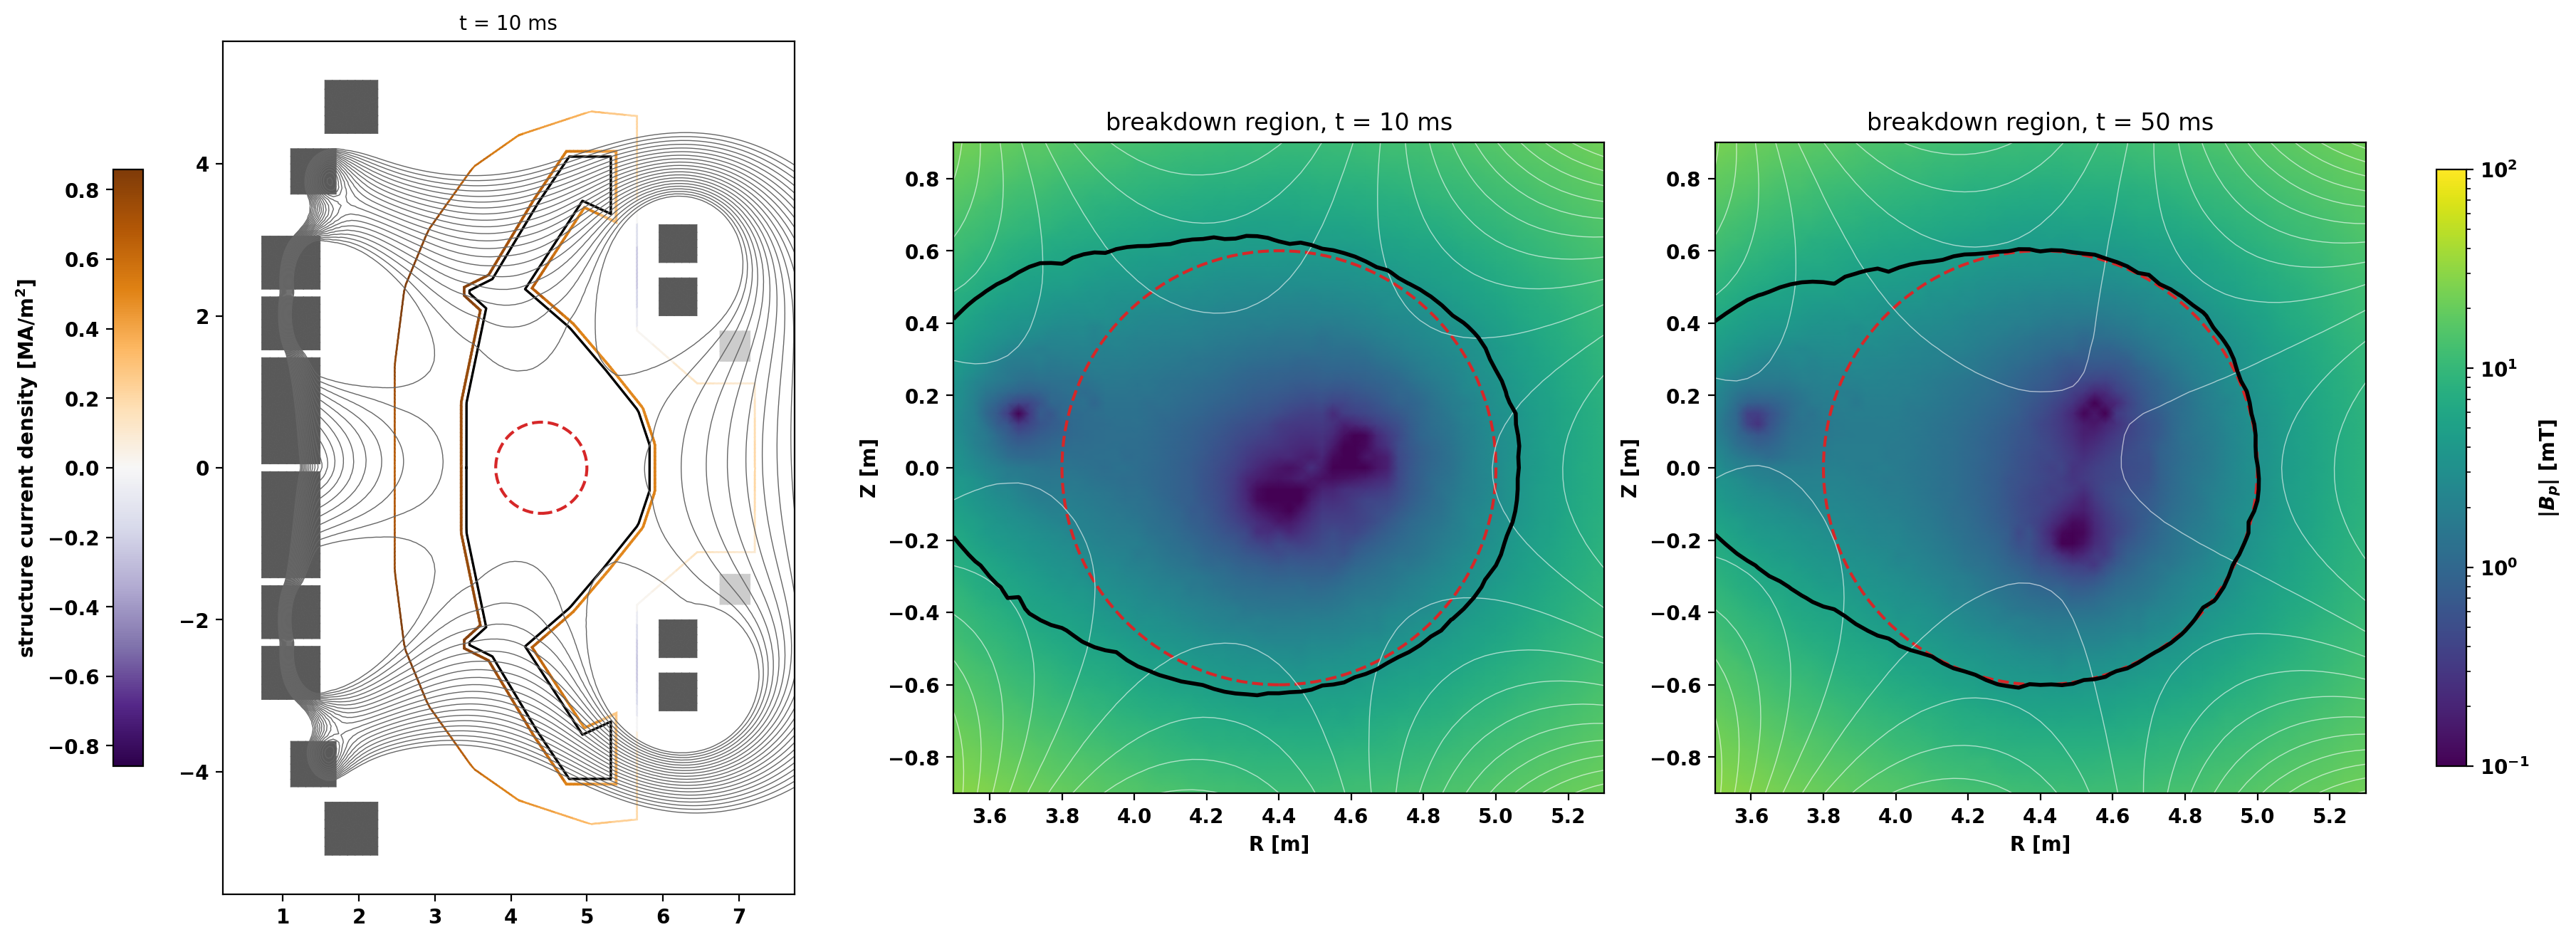

In [13]:
Jlim = np.percentile(np.abs(res_alone['I_struct'] / geom.seg_area), 99.5) / 1e6
thr = STAGE1['breakdown']['margin'] * STAGE1['breakdown']['E_star']
region = (rg['R'], rg['Z'], rg['radius'])
fig, ax = plt.subplots(1, 3, figsize=(18, 6.5), width_ratios=[1.0, 1.05, 1.05], layout='constrained')
psi_bd = splt.nodal_flux(model, circ1, res_alone['x'][k_bd])
h = splt.plot_snapshot(ax[0], geom, psi_bd, res_alone['I_struct'][k_bd], Jlim, used, title=f't = {s1.t[k_bd]*1e3:.0f} ms')
ax[0].add_patch(plt.Circle(region[:2], region[2], fill=False, ls='--', ec='C3', lw=1.5))
fig.colorbar(h, ax=ax[0], shrink=0.7, location='left', label='structure current density [MA/m$^2$]')
for a, k in zip(ax[1:], (s1.K[0], s1.K[-1])):
    mp = splt.field_maps(model, circ1, res_alone['x'][k], res_alone['xdot'][k], s1.s, (3.5, 5.3), (-0.9, 0.9))
    hb = splt.plot_breakdown_map(a, mp, geom, region, thr, title=f'breakdown region, t = {s1.t[k]*1e3:.0f} ms')
fig.colorbar(hb, ax=ax[1:], shrink=0.7, label='$|B_p|$ [mT]')
plt.show()

### The early plasma channel
Once the window ends the channel current rises to 100 kA. Left, the plasma current: it pauses at about 88 kA between 0.3 and 0.4 s, which the monotone-current constraint allows (it forbids only a fall). Middle, the radial force balance: the external vertical field at the channel stays within the allowed band around the Shafranov requirement, which grows with $I_p$. Right, the decay index stays in the stable band $0 \le n \le 1$.

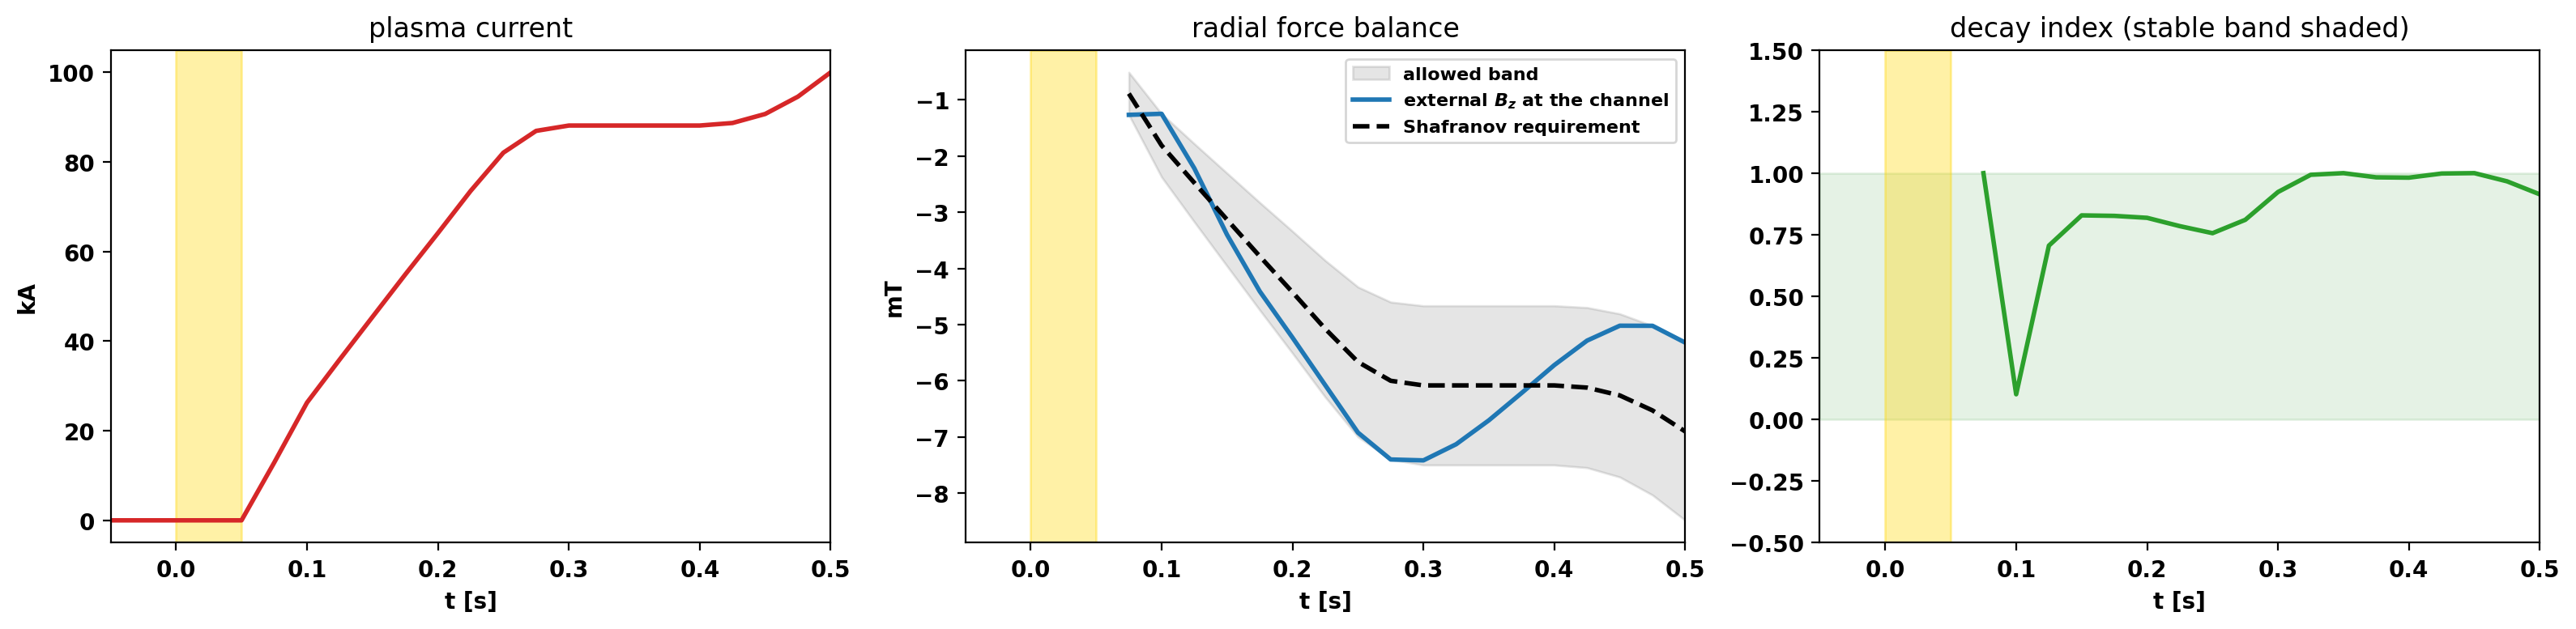

In [14]:
tt = res_alone['t']
after = tt > STAGE1['breakdown']['window'][1] + 1e-9
kf = 4e-7*np.pi/(4*np.pi*pl['Rc']) * (np.log(8*pl['Rc']/pl['a']) + pl['li']/2 - 1.5)
req = -kf * res_alone['Ip'] * 1e3
tol = pl['force_balance']['frac'] * np.abs(req) + pl['force_balance']['B_tol'] * 1e3
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(tt, s1.s * res_alone['Ip'] / 1e3, 'C3'); ax[0].set(title='plasma current', ylabel='kA')
ax[1].fill_between(tt[after], (req - tol)[after], (req + tol)[after], color='k', alpha=0.1, label='allowed band')
ax[1].plot(tt[after], res_alone['Bz_ext_c'][after] * 1e3, label='external $B_z$ at the channel')
ax[1].plot(tt[after], req[after], 'k--', label='Shafranov requirement')
ax[1].set(title='radial force balance', ylabel='mT'); ax[1].legend(fontsize=8)
ax[2].plot(tt[after], res_alone['n_c'][after], 'C2'); ax[2].axhspan(0, 1, color='g', alpha=0.1)
ax[2].set(title='decay index (stable band shaded)', ylim=(-0.5, 1.5))
for a in ax:
    a.set_xlabel('t [s]'); a.axvspan(*STAGE1['breakdown']['window'], color='gold', alpha=0.35); a.set_xlim(-0.05, tt[-1])
fig.tight_layout()
plt.show()

## 5. Will the gas actually break down?

The Leuer criterion is a compact stand-in for the avalanche physics. We can check that physics directly at the first window step:

 - **Connection length $L_c$.** Follow magnetic field lines (the poloidal field of the solution plus the toroidal field $F_0/R$) from points in the region until they hit the wall. An electron can only multiply over this distance.
 - **Townsend avalanche.** In hydrogen an electron makes $\alpha = A\,p\,e^{-Bp/E}$ ionisations per metre at pressure $p$. The avalanche runs away when $\alpha L_c \ge 1$. For a given $E_\phi$ and $L_c$ this holds over a range of prefill pressures, the **avalanche window**. A wide window that contains the planned prefill pressure means a robust breakdown.

  R = 4.40 m, Z = +0.00 m:  L_c =  31.86 km
  R = 4.70 m, Z = +0.00 m:  L_c =  13.76 km
  R = 4.10 m, Z = +0.00 m:  L_c =  11.11 km
  R = 4.40 m, Z = +0.30 m:  L_c =   8.63 km
  R = 4.40 m, Z = -0.30 m:  L_c =   8.12 km
  R = 4.90 m, Z = +0.00 m:  L_c =   4.10 km
  R = 3.90 m, Z = +0.00 m:  L_c =   9.95 km
median E_phi = 0.381 V/m, median L_c = 9.9 km
avalanche window (H2): 0.03 to 28.3 mPa


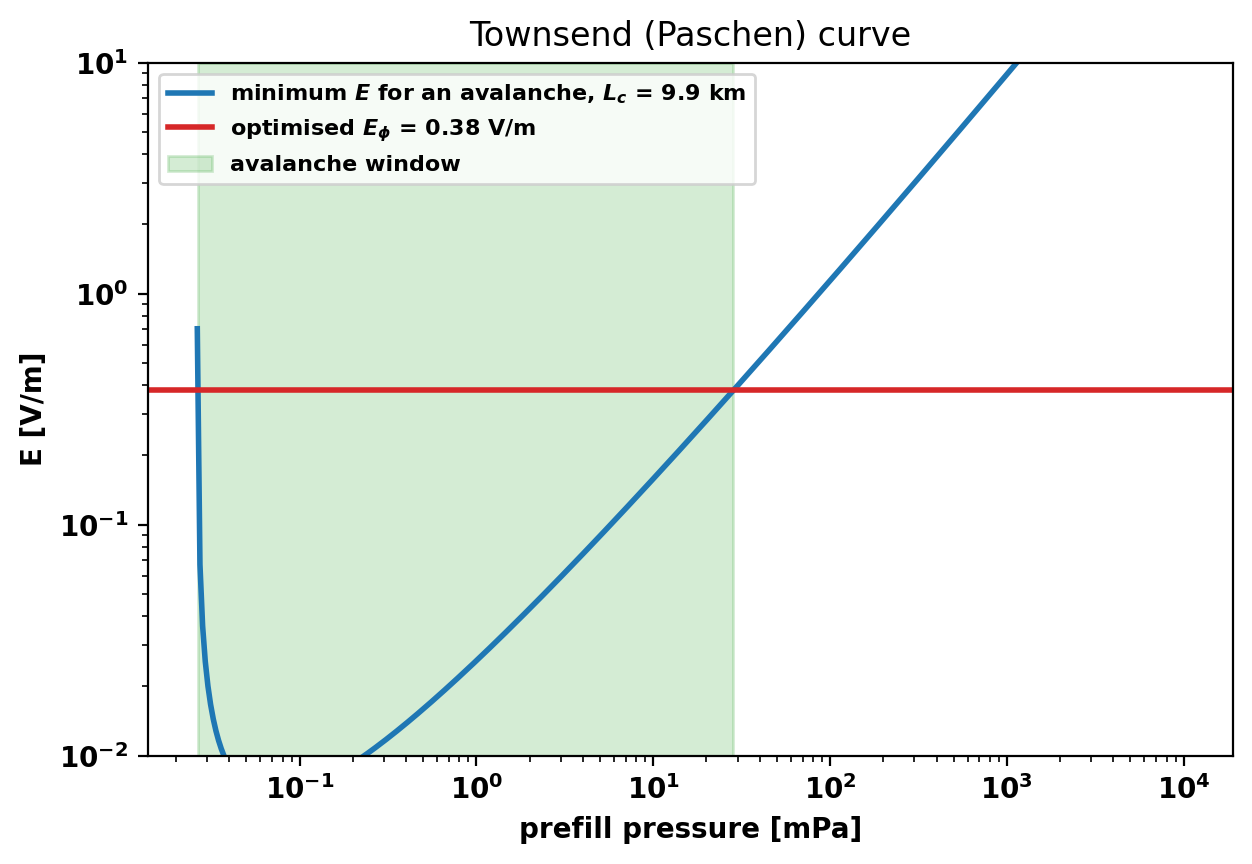

In [15]:
wall = max(mygs.lim_contours, key=len)
tracer = FieldTracer(mygs, psi_bd, F0, wall)
probe = [(rg['R'] + dR, rg['Z'] + dZ) for dR, dZ in [(0, 0), (0.3, 0), (-0.3, 0), (0, 0.3), (0, -0.3), (0.5, 0), (-0.5, 0)]]
Lc = np.array([tracer.connection_length(np.array(p)) for p in probe])
for p, L in zip(probe, Lc):
    print(f'  R = {p[0]:.2f} m, Z = {p[1]:+.2f} m:  L_c = {L/1e3:6.2f} km')
E_med = float(np.median(res_alone['E_pts'][k_bd]))
win = townsend_window(E_med, float(np.median(Lc)))
print(f'median E_phi = {E_med:.3f} V/m, median L_c = {np.median(Lc)/1e3:.1f} km')
print(f'avalanche window (H2): {win[0]*1e3:.2f} to {win[1]*1e3:.1f} mPa' if win else 'no avalanche window')

p = np.logspace(-5, 1, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(p*1e3, paschen_Emin(p, np.median(Lc)), label=f'minimum $E$ for an avalanche, $L_c$ = {np.median(Lc)/1e3:.1f} km')
ax.axhline(E_med, color='C3', label=f'optimised $E_\\phi$ = {E_med:.2f} V/m')
if win:
    ax.axvspan(win[0]*1e3, win[1]*1e3, color='C2', alpha=0.2, label='avalanche window')
ax.set(xlabel='prefill pressure [mPa]', ylabel='E [V/m]', ylim=(0.01, 10), title='Townsend (Paschen) curve')
ax.legend(fontsize=8)
plt.show()

## 6. Stage 2: ramp the plasma with TokaMaker equilibria

From 100 kA on, the plasma is a proper equilibrium, so the channel is replaced by TokaMaker free-boundary Grad-Shafranov solutions, one every 0.1 s from 0.5 s to 1.8 s. $I_p(t)$ and the target boundary of each slice are prescribed (isoflux targets). The coil voltages must hold that boundary within the coil and voltage limits, with the same exact circuit dynamics as stage 1. TokaMaker and the circuit are coupled by a **Picard iteration**:

 1. **TokaMaker step.** Solve every slice with its target shape and $I_p$, with the coil and structure currents pinned to the current trajectory by a strong regularisation (`set_coil_reg`). This gives the plasma's own flux $\psi_p$ in each slice: the total flux minus that of the coils and structure.
 2. **Convex step.** With $\psi_p$ held fixed, the plasma is a known source. The change of its flux linkage with every coil and segment drives the circuit, and its flux at the target boundary enters the shape terms. One convex problem then chooses the voltages:
    - The shape is held by a least-squares term: the external plus plasma flux at the target points should equal the boundary flux $\psi_b$ of that slice, weighted so that a 2 cm boundary error costs 1.
    - A 0-D Ohm's law sets $\psi_b$, in energy form $V_b I_p = R_p I_p^2 + \frac{d}{dt}\left(\frac{1}{2} L_i I_p^2\right)$. Here $R_p$ is the Spitzer resistance from the prescribed $T_e$, and the internal inductance $L_i = \mu_0 R\, l_i/2$ comes from each TokaMaker equilibrium.
 3. **Repeat** until the currents, TokaMaker's response and the plasma flux all stop changing.

**Joint optimisation with stage 1.** Solved on its own, stage 1 only maximises the flux at the hand-off and knows nothing about what the ramp needs. Its last voltages can then be the opposite of the ramp's first ones. Instead, every convex problem of the Picard loop contains **all of stage 1's variables and constraints** as well as the ramp's:

 - the hand-off state is an affine function of the stage-1 variables, not a fixed vector;
 - stage 1's flux objective becomes a floor: the hand-off flux may drop by at most `flux_slack_Wb` = 0.2 Wb below its stand-alone optimum (flux first, then the ramp);
 - the voltage smoothing covers the whole time the plasma carries current, from the end of the breakdown window, across the hand-off, to the end of the ramp.

The breakdown constraints remain hard constraints throughout, so the breakdown found jointly is still a valid breakdown. This step takes about 3.5 minutes.

In [16]:
ramp = GSRamp(model, circ2, RAMP, s1)
t0 = time.time()
converged = ramp.run(max_iter=RAMP['ramp']['max_iter'])
print(f'Picard loop converged: {converged} after {len(ramp.history)} iterations ({time.time()-t0:.0f} s)')
res = s1.results()          # stage 1 now holds the jointly optimised trajectory
summ = ramp.summary()
print(f"hand-off flux: {summ['flux_handoff_standalone_Wb']:.2f} Wb (stage 1 alone) -> {summ['flux_handoff_Wb']:.2f} Wb (joint)")
print(f"plasma boundary flux: {summ['flux_boundary_handoff_Wb']:.2f} Wb at the hand-off -> {summ['flux_boundary_end_Wb']:.2f} Wb at 1.8 s "
      f"(ramp cost {summ['ramp_flux_cost_Wb']:.2f} Wb)")
print(f"largest boundary error over the ramp: {summ['shape_err_max_cm']:.1f} cm")
print(f"largest voltage step after breakdown: {summ['dV_max_after_breakdown']:.2f} V_max")

  Picard 0: Solved   current change 9.0e-01, TokaMaker deviation 7.8e-04, plasma flux change 6.0e-03, max shape error 2.69 cm
  Picard 1: Solved   current change 7.4e-02, TokaMaker deviation 7.3e-04, plasma flux change 2.9e-03, max shape error 2.57 cm
  Picard 2: AlmostSolved current change 2.5e-02, TokaMaker deviation 7.3e-04, plasma flux change 1.4e-03, max shape error 2.54 cm
  Picard 3: Solved   current change 8.3e-03, TokaMaker deviation 7.3e-04, plasma flux change 6.5e-04, max shape error 2.52 cm
  Picard 4: AlmostSolved current change 3.1e-03, TokaMaker deviation 7.3e-04, plasma flux change 3.1e-04, max shape error 2.51 cm
  Picard 5: AlmostSolved current change 1.3e-03, TokaMaker deviation 7.3e-04, plasma flux change 1.5e-04, max shape error 2.51 cm
Picard loop converged: True after 6 iterations (222 s)
hand-off flux: 82.31 Wb (stage 1 alone) -> 82.11 Wb (joint)
plasma boundary flux: 83.19 Wb at the hand-off -> 79.58 Wb at 1.8 s (ramp cost 3.62 Wb)
largest boundary error over t

## 7. The whole start-up

The dotted line marks the hand-off from stage 1 to the TokaMaker ramp. Things to look for:

 - The plasma current is continuous at the hand-off, and TokaMaker's equilibria (crosses) carry exactly the prescribed $I_p$.
 - The coil currents are continuous across the hand-off, and the supply voltages have no reversals: the largest step anywhere after breakdown is printed above, because both stages were optimised together.
 - The flux available to the pulse falls as the ramp spends it on resistive and inductive losses, following the 0-D Ohm's law. The two flux curves are different quantities: stage 1 reports the external flux at the centre of the breakdown region, and the ramp reports the flux at the plasma boundary, so they need not meet at the hand-off.

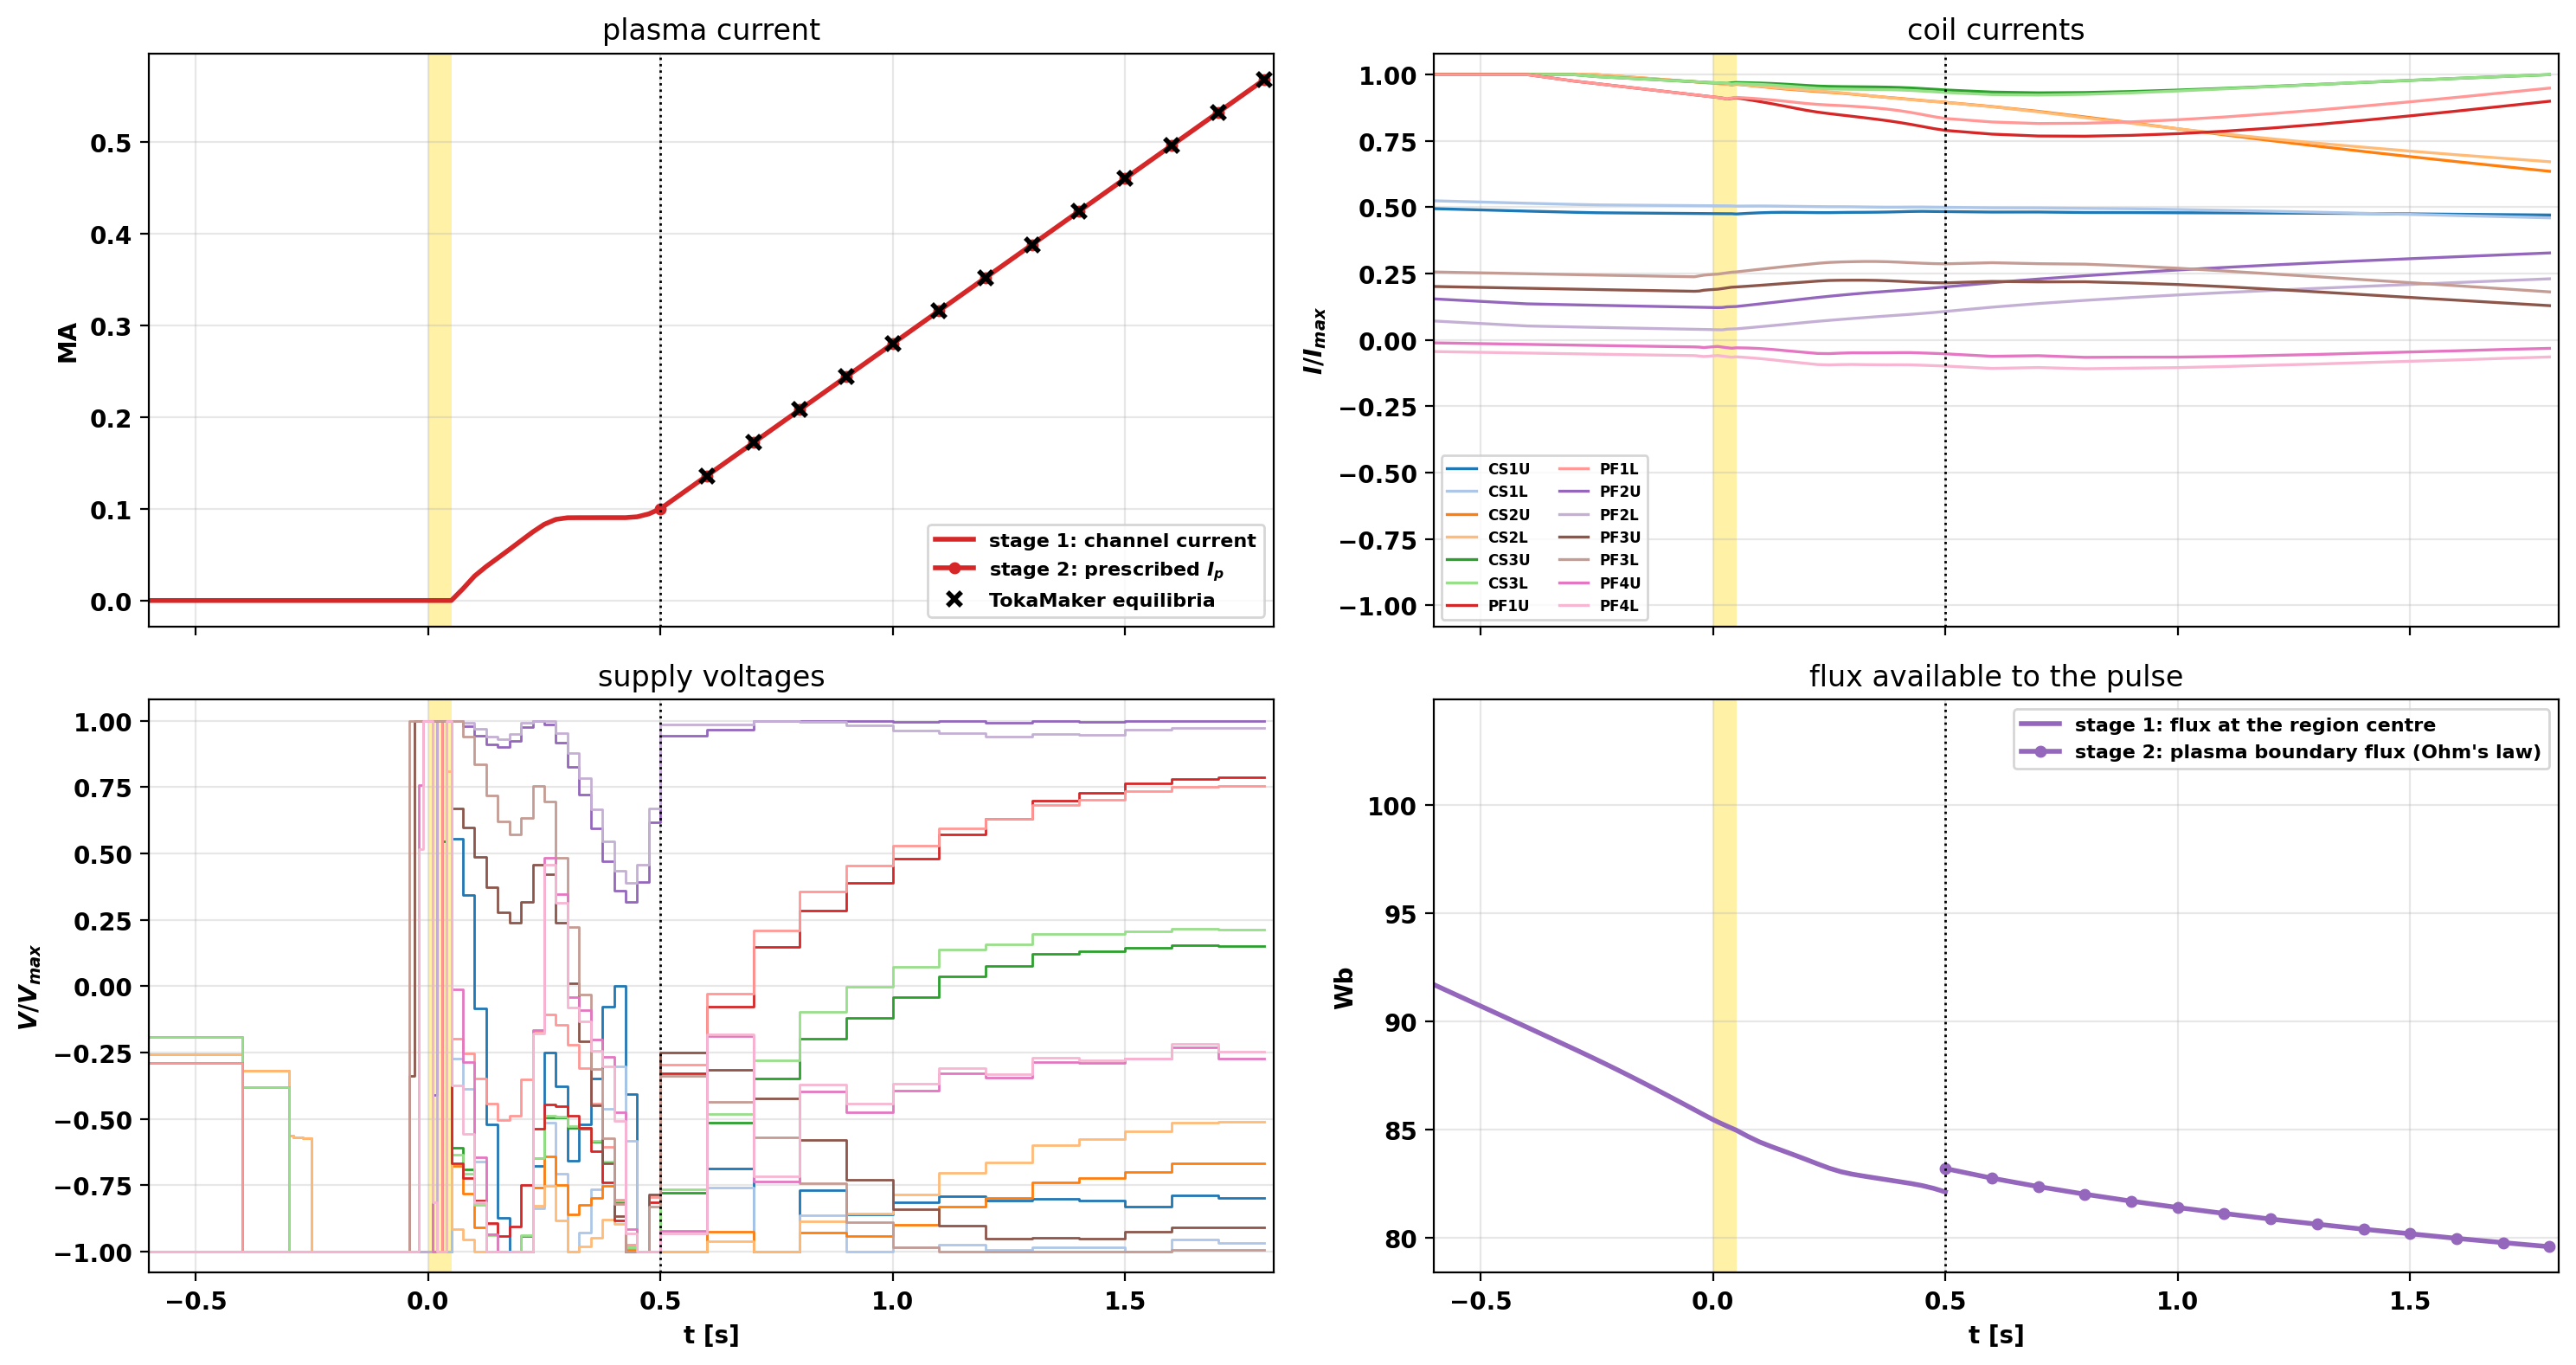

In [17]:
fig = splt.plot_pulse(s1, ramp, res)
plt.show()

### Snapshots
The whole machine at six times, from premagnetisation through breakdown and the hand-off to the end of the ramp:

 - structure segments are coloured by eddy-current density;
 - grey lines are flux contours;
 - on the ramp slices, the red line is TokaMaker's last closed flux surface and the orange crosses are the target boundary points.

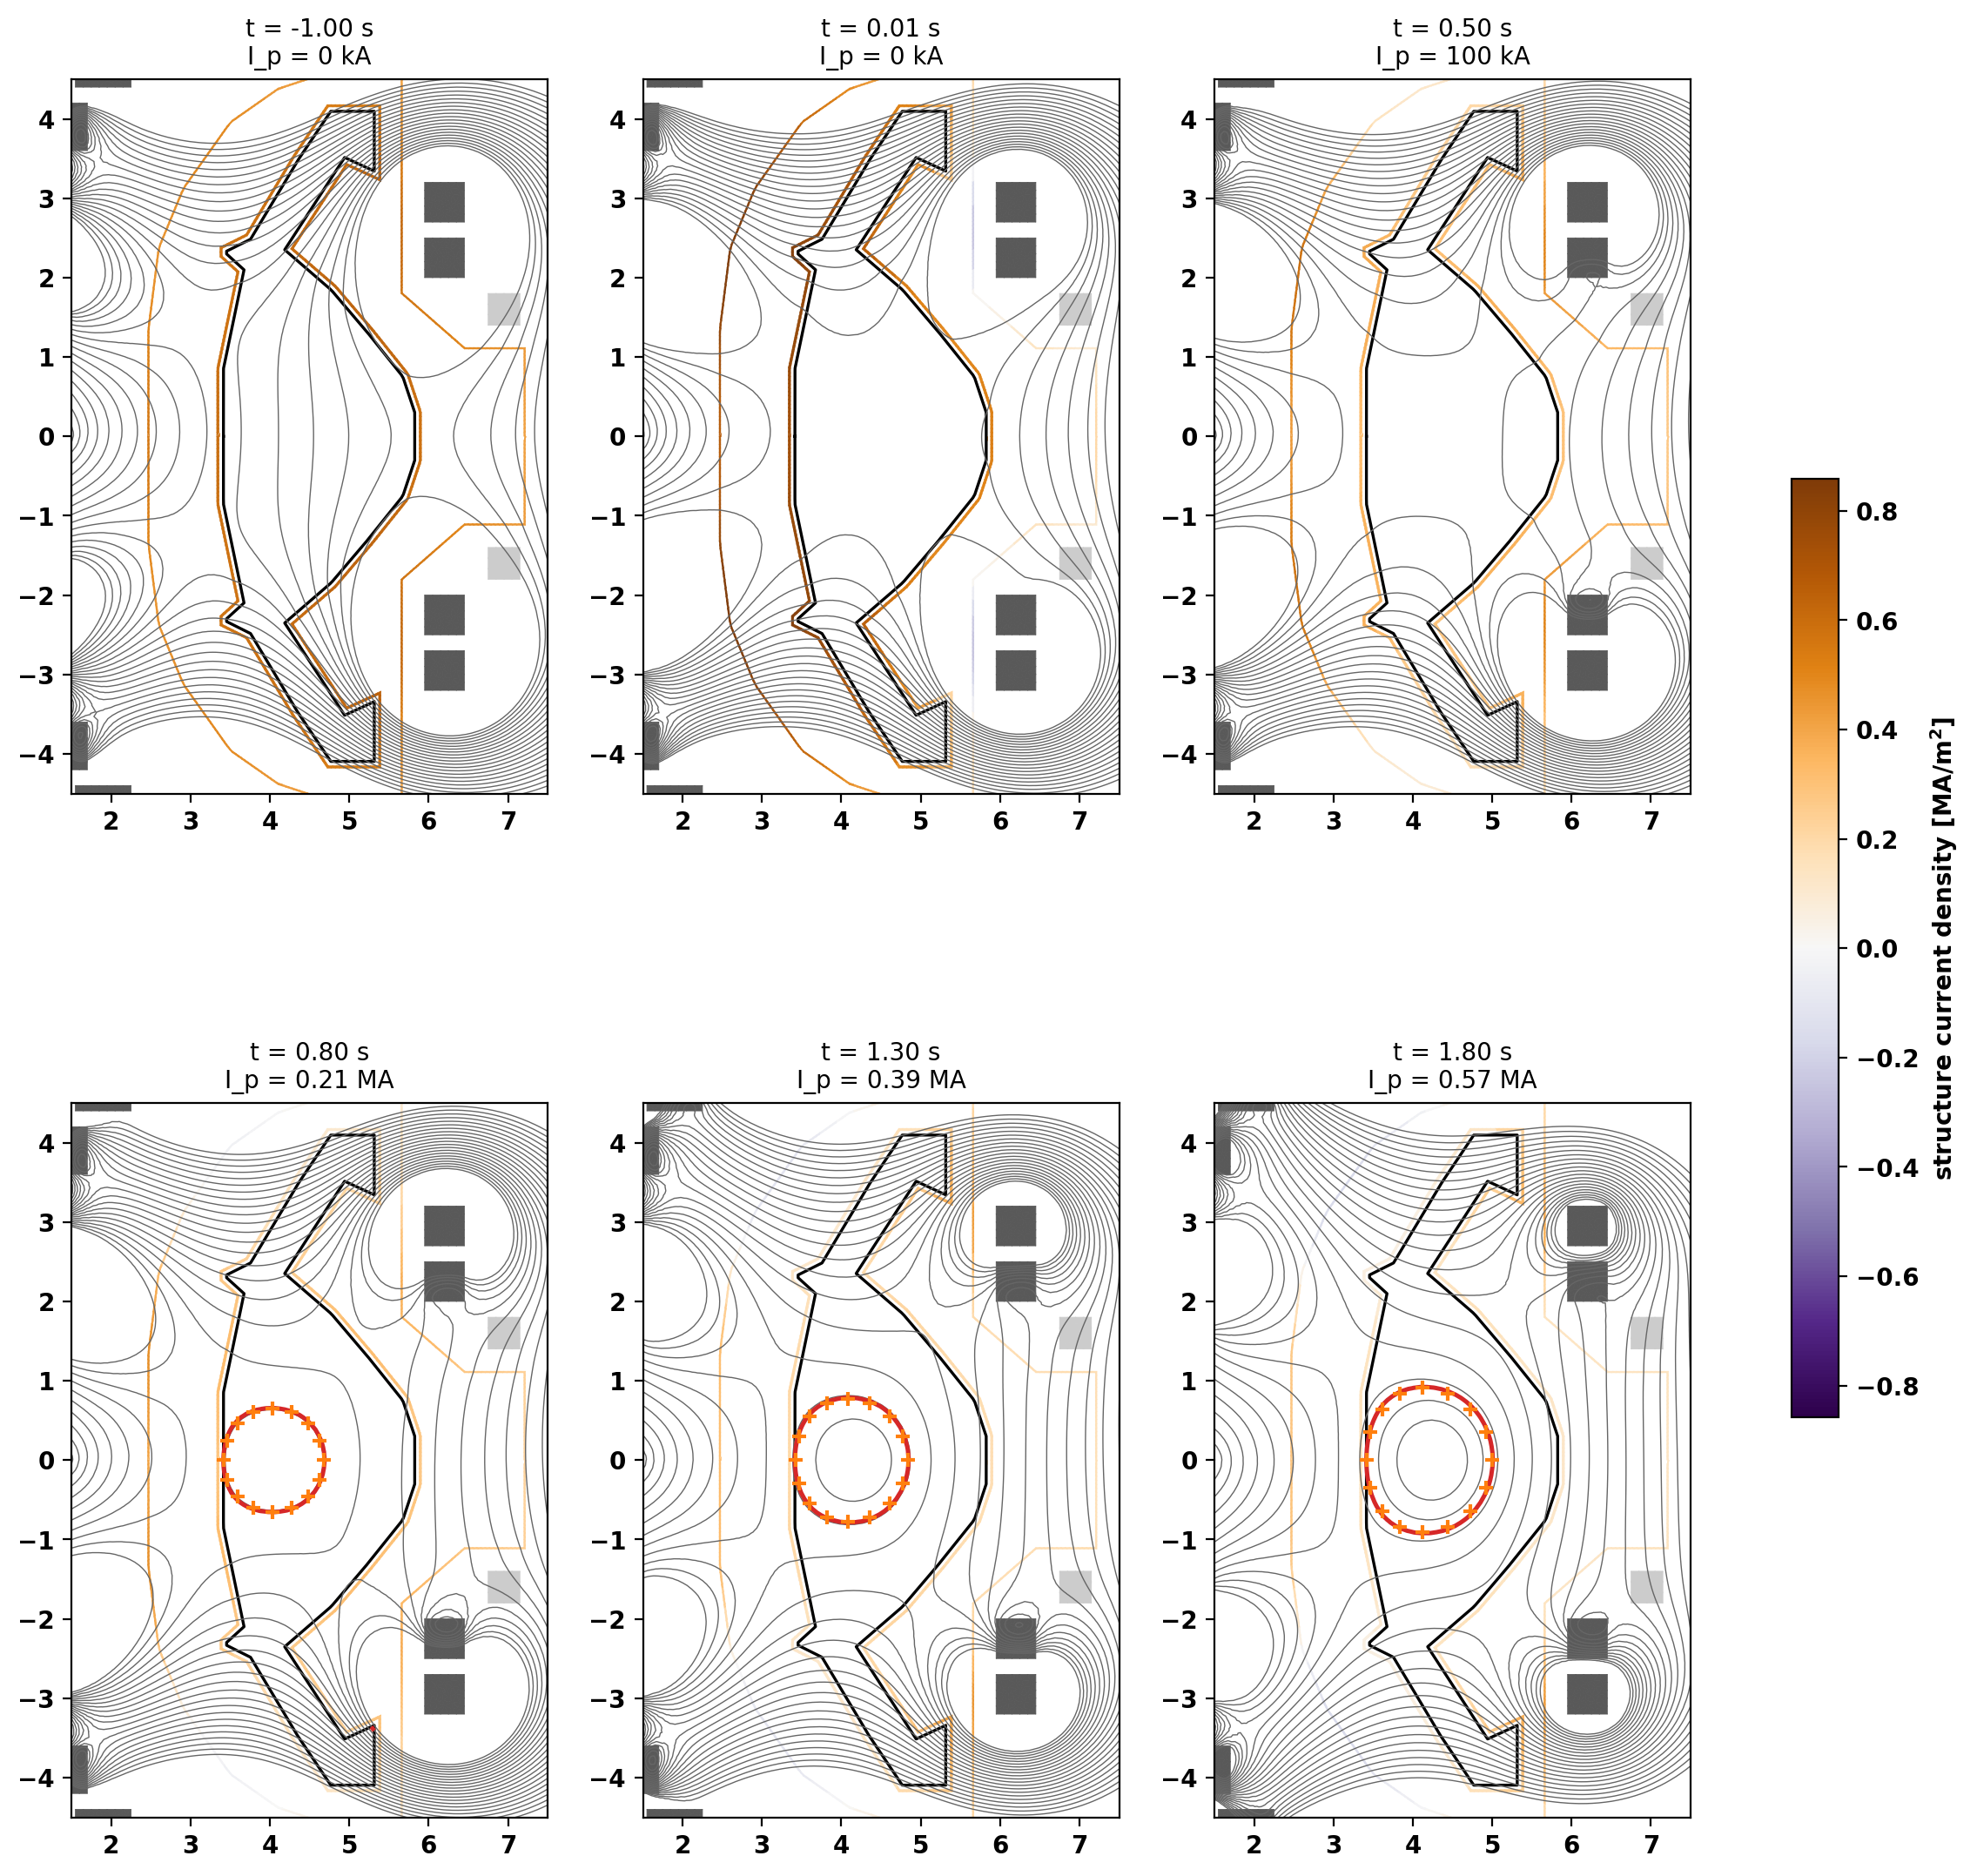

In [18]:
snaps = [('stage 1', int(np.argmin(np.abs(s1.t + 1.0)))), ('stage 1', s1.K[0]), ('stage 1', len(s1.t) - 1),
         ('ramp', 3), ('ramp', 8), ('ramp', len(ramp.t) - 1)]
Jlim = np.percentile(np.abs(res['I_struct'] / geom.seg_area), 99.5) / 1e6
fig, ax = plt.subplots(2, 3, figsize=(15, 14))
for a, (stage, k) in zip(ax.ravel(), snaps):
    if stage == 'stage 1':
        psi = splt.nodal_flux(model, circ1, res['x'][k], s1.plasma, res['Ip'][k])
        h = splt.plot_snapshot(a, geom, psi, res['I_struct'][k], Jlim, used,
                               title=f't = {s1.t[k]:.2f} s\nI_p = {s1.s*res["Ip"][k]/1e3:.0f} kA')
    else:
        h = splt.plot_snapshot(a, geom, ramp.psi_tot[k], ramp.x[k][circ2.ncirc:], Jlim, used,
                               lcfs=ramp.tm_info[k]['psi_bounds'][0], iso=ramp.iso[k],
                               title=f't = {ramp.t[k]:.2f} s\nI_p = {ramp.Ip[k]/1e6:.2f} MA')
    a.set_xlim(1.5, 7.5); a.set_ylim(-4.5, 4.5)
fig.colorbar(h, ax=ax, shrink=0.5, label='structure current density [MA/m$^2$]')
plt.show()

### What did the joint optimisation change?
The supply voltages of the coils that changed most, with stage 1 solved alone (dashed) and jointly with the ramp (solid). The joint solution trades at most 0.2 Wb of hand-off flux for voltages that lead smoothly into the ramp. Before breakdown the two solutions are nearly identical, since the premagnetisation swing and the breakdown window are set by the breakdown constraints.

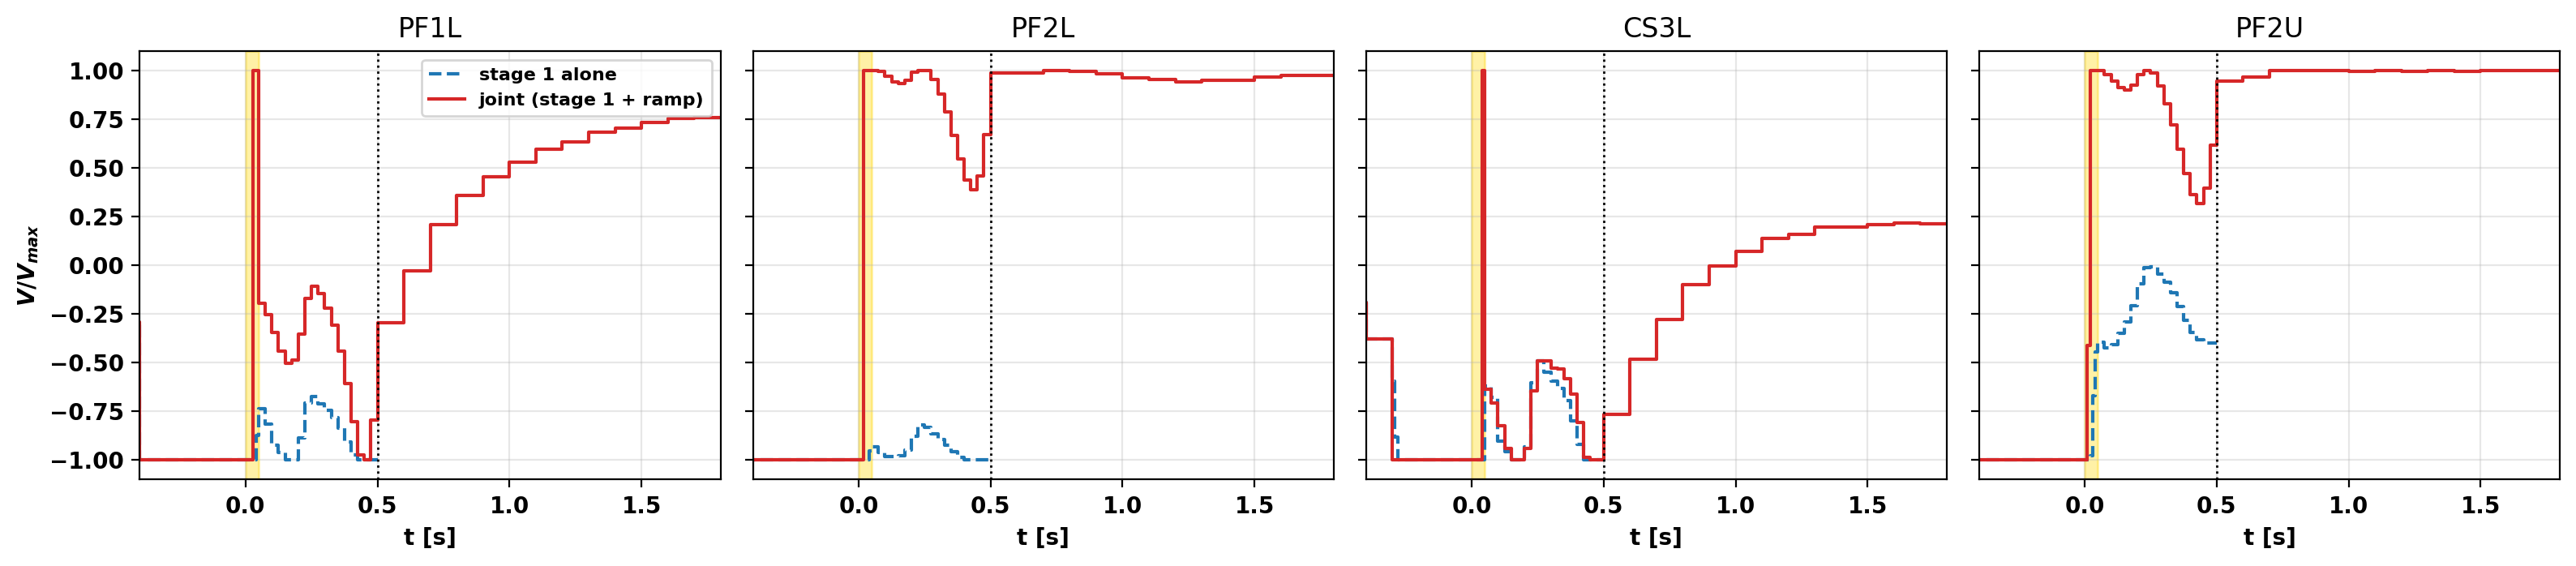

In [19]:
dv = np.abs(res['V'] - res_alone['V']).max(axis=0) / circ1.V_max
top = np.argsort(dv)[::-1][:4]
t1, t2 = s1.t, ramp.t
stairs = lambda t, v: (np.repeat(t, 2)[1:-1], np.repeat(v, 2))
fig, ax = plt.subplots(1, len(top), figsize=(16, 3.6), sharey=True)
for a, j in zip(ax, top):
    a.plot(*stairs(t1, res_alone['V'][:, j] / V_MAX), 'C0--', lw=1.5, label='stage 1 alone')
    a.plot(*stairs(np.r_[t1, t2[1:]], np.r_[res['V'][:, j], ramp.V[:, j]] / V_MAX), 'C3', lw=1.5, label='joint (stage 1 + ramp)')
    a.axvline(t2[0], color='k', ls=':', lw=1); a.axvspan(*STAGE1['breakdown']['window'], color='gold', alpha=0.35)
    a.set(title=circ1.circ_names[j], xlabel='t [s]', xlim=(-0.4, t2[-1])); a.grid(alpha=0.3)
ax[0].set_ylabel('$V / V_{max}$'); ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Summary

In [20]:
rows = [('flux left at the hand-off, stage 1 alone', f"{summ['flux_handoff_standalone_Wb']:.2f} Wb"),
        ('flux left at the hand-off, joint', f"{summ['flux_handoff_Wb']:.2f} Wb"),
        ('breakdown: min s*E_phi / max |B_p| (first window step)', f"{res['E_pts'][k_bd].min():.3f} V/m / {res['B_pts'][k_bd].max()*1e3:.2f} mT"),
        ('connection length (median of probes)', f'{np.median(Lc)/1e3:.1f} km'),
        ('avalanche window (H2)', f'{win[0]*1e3:.2f} to {win[1]*1e3:.0f} mPa' if win else 'none'),
        ('plasma current at the hand-off / end of ramp', f"{s1.s*res['Ip'][-1]/1e3:.0f} kA / {ramp.Ip[-1]/1e6:.2f} MA"),
        ('plasma boundary flux at the end of the ramp', f"{summ['flux_boundary_end_Wb']:.2f} Wb"),
        ('ramp converged / Picard iterations', f"{converged} / {summ['picard_iterations']}"),
        ('largest boundary error over the ramp', f"{summ['shape_err_max_cm']:.1f} cm"),
        ('largest voltage step after breakdown', f"{summ['dV_max_after_breakdown']:.2f} V_max")]
w = max(len(r[0]) for r in rows)
for k_, v_ in rows:
    print(f'{k_:<{w}}  {v_}')

flux left at the hand-off, stage 1 alone                82.31 Wb
flux left at the hand-off, joint                        82.11 Wb
breakdown: min s*E_phi / max |B_p| (first window step)  0.355 V/m / 4.11 mT
connection length (median of probes)                    9.9 km
avalanche window (H2)                                   0.03 to 28 mPa
plasma current at the hand-off / end of ramp            100 kA / 0.57 MA
plasma boundary flux at the end of the ramp             79.58 Wb
ramp converged / Picard iterations                      True / 6
largest boundary error over the ramp                    2.5 cm
largest voltage step after breakdown                    0.84 V_max


### Model limitations
This example is meant to show the workflow; several inputs are placeholders that a real design study would replace:

 - **Burn-through.** The channel temperature $T_e(t)$ and the ramp's $T_e$ keyframes are prescribed rather than computed by a burn-through or transport model.
 - **Breakdown threshold.** The Leuer threshold $E^* = 1000$ V/m and the $\pm 5$ kV supply limit are working values.
 - **Fixed channel.** The early channel sits where the first equilibrium will be. A channel that forms at the field null and migrates would need a burn-through model to place it.
 - **Ramp length.** The ramp stops at 0.57 MA. Beyond about 1.8 s these target shapes and profiles become hard for TokaMaker to converge.

### Where to go from here
The same model supports the questions a start-up design study asks next, each by changing an input and re-solving:

 - **Robustness.** Raise the Leuer margin $m$ for a breakdown that tolerates field errors or a pessimistic $E^*$, and measure what it costs in flux.
 - **Supplies.** Compare supply voltages, for example the effect of a lower voltage with electron-cyclotron assisted breakdown.
 - **Breakdown position.** Move the breakdown region, inboard or outboard, and compare the flux and the ramp.
 - **Hardware value.** Read the dual variables of the stage-1 problem as the flux gained per kV of supply voltage or per kA of coil current.